# Ortogonalidad: bases ortonormales, proyecciones, Gram-Schmidt y mínimos cuadrados

En el [Cuaderno11](Cuaderno11.ipynb) observamos que $\operatorname{Nul}(A)$ es perpendicular a $\operatorname{Fil}(A)$. En este cuaderno convertimos la perpendicularidad en una herramienta de cálculo y respondemos:

1. ¿Por qué las bases **ortogonales** simplifican tanto los cálculos?
2. ¿Cuál es el punto de un subespacio $W$ más cercano a un vector $y$? $\;\to\;$ **proyección ortogonal**
3. ¿Qué vectores son perpendiculares a todo $W$? $\;\to\;$ **complemento ortogonal**
4. ¿Cómo convertir cualquier base en una base ortogonal? $\;\to\;$ **proceso de Gram-Schmidt** y factorización $QR$
5. ¿Qué hacer con un sistema $Ax=b$ que **no tiene solución**? $\;\to\;$ **mínimos cuadrados**

## 1. Repaso: producto punto, norma y ortogonalidad

Para $u,v\in\mathbb{R}^n$:

| Concepto | Fórmula |
|---|---|
| Producto punto | $u\cdot v=u^Tv=u_1v_1+\dots+u_nv_n$ |
| Norma (longitud) | $\lVert u\rVert=\sqrt{u\cdot u}$ |
| Distancia | $\operatorname{dist}(u,v)=\lVert u-v\rVert$ |
| Ortogonalidad | $u\perp v\iff u\cdot v=0$ |
| Vector unitario | $\lVert u\rVert=1$. Normalizar: $\dfrac{u}{\lVert u\rVert}$ |

**Teorema de Pitágoras.** $u\perp v\iff\lVert u+v\rVert^2=\lVert u\rVert^2+\lVert v\rVert^2$.

*Prueba.* $\lVert u+v\rVert^2=(u+v)\cdot(u+v)=\lVert u\rVert^2+2\,u\cdot v+\lVert v\rVert^2$, y el término del medio es cero exactamente cuando $u\cdot v=0$. $\blacksquare$

## 2. Conjuntos y bases ortogonales

**Definición.** Un conjunto $\{u_1,\dots,u_p\}\subset\mathbb{R}^n$ es **ortogonal** si $u_i\cdot u_j=0$ para todo $i\neq j$. Es **ortonormal** si además $\lVert u_i\rVert=1$ para todo $i$.

**Teorema.** Todo conjunto ortogonal de vectores **no nulos** es linealmente independiente.

*Prueba.* Suponga $c_1u_1+\dots+c_pu_p=\mathbf 0$. Haciendo producto punto con $u_j$, todos los términos se anulan excepto uno:
$$c_j\,(u_j\cdot u_j)=0\quad\Longrightarrow\quad c_j\lVert u_j\rVert^2=0\quad\Longrightarrow\quad c_j=0,$$
porque $u_j\neq\mathbf 0$. Como esto vale para cada $j$, el conjunto es LI. $\blacksquare$

**Consecuencia.** Si $W$ tiene dimensión $p$, cualquier conjunto ortogonal de $p$ vectores no nulos de $W$ es una base de $W$: una **base ortogonal**. Si además son unitarios, es una **base ortonormal**.

### 2.1 Coordenadas sin resolver sistemas

En el [Cuaderno10](Cuaderno10.ipynb), hallar las coordenadas de un vector en una base exigía resolver un sistema. Con una base ortogonal basta un producto punto por coordenada.

**Teorema.** Si $\{u_1,\dots,u_p\}$ es una base ortogonal de $W$ y $y\in W$, entonces
$$y=c_1u_1+\dots+c_pu_p\qquad\text{con}\qquad \boxed{c_j=\frac{y\cdot u_j}{u_j\cdot u_j}}.$$

*Prueba.* Igual que antes: el producto punto de $y=c_1u_1+\dots+c_pu_p$ con $u_j$ da $y\cdot u_j=c_j\,(u_j\cdot u_j)$. $\blacksquare$

**Ejemplo.** Sean
$$u_1=\begin{pmatrix}1\\1\\1\end{pmatrix},\qquad u_2=\begin{pmatrix}1\\-1\\0\end{pmatrix},\qquad u_3=\begin{pmatrix}1\\1\\-2\end{pmatrix}.$$
Como $u_1\cdot u_2=0$, $u_1\cdot u_3=1+1-2=0$ y $u_2\cdot u_3=1-1+0=0$, el conjunto es ortogonal; tiene 3 vectores no nulos en $\mathbb{R}^3$, luego es una base ortogonal $\mathcal B$ de $\mathbb{R}^3$.

Para $y=(6,2,1)$:
$$c_1=\frac{6+2+1}{3}=3,\qquad c_2=\frac{6-2+0}{2}=2,\qquad c_3=\frac{6+2-2}{6}=1,$$
así que $[y]_{\mathcal B}=(3,2,1)$. Comprobación: $3(1,1,1)+2(1,-1,0)+1(1,1,-2)=(6,2,1)$. ✓

### 2.2 Bases ortonormales y matrices ortogonales

Si la base es **ortonormal**, el denominador $u_j\cdot u_j$ vale $1$ y la fórmula queda $c_j=y\cdot u_j$. Normalizando el ejemplo anterior:
$$q_1=\tfrac{1}{\sqrt3}(1,1,1),\qquad q_2=\tfrac{1}{\sqrt2}(1,-1,0),\qquad q_3=\tfrac{1}{\sqrt6}(1,1,-2).$$

**Teorema.** Una matriz $U$ de tamaño $m\times n$ tiene columnas ortonormales si y solo si
$$U^TU=I_n .$$
La razón es que la entrada $(i,j)$ de $U^TU$ es $u_i\cdot u_j$, que debe valer $1$ si $i=j$ y $0$ si $i\neq j$.

Una matriz así **preserva longitudes y ángulos**: para todo $x,y\in\mathbb{R}^n$,
$$\lVert Ux\rVert=\lVert x\rVert,\qquad (Ux)\cdot(Uy)=x\cdot y,$$
porque $(Ux)\cdot(Uy)=x^TU^TUy=x^Ty$.

**Matriz ortogonal.** Si $Q$ es **cuadrada** con columnas ortonormales, se llama *matriz ortogonal* y cumple
$$Q^{-1}=Q^T .$$
Ejemplos: las rotaciones $\begin{pmatrix}\cos\theta&-\sin\theta\\ \sin\theta&\cos\theta\end{pmatrix}$, las reflexiones y las matrices de permutación.

**Cambio de base gratis.** Si $\mathcal B=\{q_1,\dots,q_n\}$ es una base ortonormal de $\mathbb{R}^n$ y $Q=[\,q_1\ \cdots\ q_n\,]$, entonces $y=Q[y]_{\mathcal B}$ y, en vez de invertir $Q$,
$$[y]_{\mathcal B}=Q^Ty .$$

## 3. Proyecciones ortogonales

### 3.1 Proyección sobre una recta

Sea $u\neq\mathbf 0$ y $L=\operatorname{gen}\{u\}$. Queremos escribir
$$y=\hat y+z,\qquad \hat y=\alpha u\in L,\qquad z\perp u .$$
La condición $z\cdot u=(y-\alpha u)\cdot u=0$ da $\alpha=\dfrac{y\cdot u}{u\cdot u}$. Por tanto
$$\boxed{\operatorname{proy}_L y=\frac{y\cdot u}{u\cdot u}\,u}\qquad\text{y}\qquad z=y-\operatorname{proy}_L y .$$
El vector $z$ es la **componente de $y$ ortogonal a $u$**, y $\lVert z\rVert$ es la distancia de $y$ a la recta $L$.

**Ejemplo.** $y=(7,6)$, $u=(4,2)$. Como $y\cdot u=28+12=40$ y $u\cdot u=20$:
$$\hat y=\tfrac{40}{20}(4,2)=(8,4),\qquad z=y-\hat y=(-1,2).$$
Comprobación: $z\cdot u=-4+4=0$. ✓ La distancia de $y$ a $L$ es $\lVert z\rVert=\sqrt5$.

Observe que los coeficientes $c_j$ de la sección 2.1 son exactamente coeficientes de proyección: **en una base ortogonal, $y$ es la suma de sus proyecciones sobre cada vector de la base**.

<p align="center"><img src="../imagenes/cuaderno12/proy_recta.png" width="560"></p>

<p align="center"><i>El vector y se descompone en su sombra sobre L más una componente perpendicular a L.</i></p>

### 3.2 Proyección sobre un subespacio: teorema de descomposición ortogonal

**Teorema (descomposición ortogonal).** Sea $W$ un subespacio de $\mathbb{R}^n$ con base **ortogonal** $\{u_1,\dots,u_p\}$. Todo $y\in\mathbb{R}^n$ se escribe de manera **única** como
$$y=\hat y+z,\qquad \hat y\in W,\qquad z\perp W\ (\text{es decir, } z\perp w \text{ para todo } w\in W),$$
donde
$$\boxed{\hat y=\operatorname{proy}_W y=\frac{y\cdot u_1}{u_1\cdot u_1}\,u_1+\dots+\frac{y\cdot u_p}{u_p\cdot u_p}\,u_p}.$$

*Prueba.* Sea $c_j=\frac{y\cdot u_j}{u_j\cdot u_j}$. Entonces $\hat y\in W$ y, para cada $j$,
$$z\cdot u_j=(y-\hat y)\cdot u_j=y\cdot u_j-c_j\,(u_j\cdot u_j)=0,$$
así que $z$ es ortogonal a cada vector de la base y por tanto a todo $W$.
Unicidad: si $\hat y+z=\hat y'+z'$, el vector $\hat y-\hat y'=z'-z$ está en $W$ y es ortogonal a $W$; en particular es ortogonal a sí mismo, luego es $\mathbf 0$. $\blacksquare$

> ⚠️ La fórmula **exige una base ortogonal**. Con una base cualquiera, sumar las proyecciones sobre cada vector **no** da la proyección sobre $W$. Por eso necesitamos Gram-Schmidt (sección 5).

**Ejemplo.** Sea $W=\operatorname{gen}\{u_1,u_2\}$ con $u_1=(1,1,1)$, $u_2=(1,-1,0)$ (un plano en $\mathbb{R}^3$) y $y=(6,2,1)$. Los coeficientes ya los calculamos en 2.1:
$$\hat y=3u_1+2u_2=(5,1,3),\qquad z=y-\hat y=(1,1,-2).$$
Comprobación: $z\cdot u_1=1+1-2=0$ y $z\cdot u_2=1-1+0=0$. ✓ (No es casualidad que $z=u_3$: el término $c_3u_3$ es justamente lo que queda fuera de $W$.) La distancia de $y$ al plano $W$ es $\lVert z\rVert=\sqrt6$.

<p align="center"><img src="../imagenes/cuaderno12/proy_plano.png" width="520"></p>

<p align="center"><i>y = ŷ + z: la proyección ŷ está en el plano W y z es perpendicular a W.</i></p>

### 3.3 El teorema de la mejor aproximación

**Teorema.** $\hat y=\operatorname{proy}_W y$ es el punto de $W$ **más cercano** a $y$:
$$\lVert y-\hat y\rVert<\lVert y-v\rVert\qquad\text{para todo } v\in W,\ v\neq\hat y .$$

*Prueba.* Escriba $y-v=(y-\hat y)+(\hat y-v)$. El primer sumando está en $W^\perp$ y el segundo en $W$, así que son ortogonales y, por Pitágoras,
$$\lVert y-v\rVert^2=\lVert y-\hat y\rVert^2+\lVert\hat y-v\rVert^2>\lVert y-\hat y\rVert^2,$$
pues $\hat y-v\neq\mathbf 0$. $\blacksquare$

Este teorema es la base de los mínimos cuadrados (sección 6): **aproximar lo mejor posible = proyectar ortogonalmente**.

### 3.4 La matriz de proyección

Si $\{q_1,\dots,q_p\}$ es una base **ortonormal** de $W$ y $U=[\,q_1\ \cdots\ q_p\,]$ ($n\times p$), la fórmula de 3.2 se vuelve
$$\operatorname{proy}_W y=(y\cdot q_1)\,q_1+\dots+(y\cdot q_p)\,q_p=UU^Ty .$$
La matriz $P=UU^T$ ($n\times n$) es la **matriz de proyección** sobre $W$. Cumple
$$P^T=P\quad(\text{simétrica}),\qquad P^2=P\quad(\text{proyectar dos veces es lo mismo que proyectar una}).$$
Ojo: $U^TU=I_p$, pero $UU^T\neq I_n$ salvo que $p=n$.

**Ejemplo.** Para el plano $W$ de 3.2, con $q_1=\tfrac1{\sqrt3}(1,1,1)$ y $q_2=\tfrac1{\sqrt2}(1,-1,0)$:
$$P=q_1q_1^T+q_2q_2^T=\frac13\begin{pmatrix}1&1&1\\1&1&1\\1&1&1\end{pmatrix}+\frac12\begin{pmatrix}1&-1&0\\-1&1&0\\0&0&0\end{pmatrix}=\begin{pmatrix}\tfrac56&-\tfrac16&\tfrac13\\[2pt]-\tfrac16&\tfrac56&\tfrac13\\[2pt]\tfrac13&\tfrac13&\tfrac13\end{pmatrix},$$
y efectivamente $P\,(6,2,1)^T=(5,1,3)^T=\hat y$.

## 4. Complemento ortogonal

**Definición.** El **complemento ortogonal** de un subespacio $W\subseteq\mathbb{R}^n$ es
$$W^\perp=\{z\in\mathbb{R}^n:\ z\cdot w=0\ \text{ para todo } w\in W\}.$$

**Propiedades.**
1. $W^\perp$ es un subespacio de $\mathbb{R}^n$.
2. Basta verificar contra un conjunto generador: si $W=\operatorname{gen}\{w_1,\dots,w_k\}$, entonces $z\in W^\perp\iff z\cdot w_i=0$ para $i=1,\dots,k$.
3. $W\cap W^\perp=\{\mathbf 0\}$ (un vector ortogonal a sí mismo es cero).
4. $\dim W+\dim W^\perp=n$.
5. $(W^\perp)^\perp=W$.
6. Todo $y\in\mathbb{R}^n$ se descompone como $y=\operatorname{proy}_W y+\operatorname{proy}_{W^\perp}y$ (es el teorema de 3.2, con $z=\operatorname{proy}_{W^\perp}y$).

### 4.1 Los cuatro subespacios fundamentales

**Teorema.** Para toda matriz $A$ de tamaño $m\times n$:
$$\boxed{(\operatorname{Fil}A)^\perp=\operatorname{Nul}A}\qquad\text{y}\qquad\boxed{(\operatorname{Col}A)^\perp=\operatorname{Nul}A^T}.$$

*Prueba.* $Ax=\mathbf 0$ dice exactamente que $f_i\cdot x=0$ para cada fila $f_i$ de $A$, es decir, que $x$ es ortogonal a todas las filas y por la propiedad 2 a todo $\operatorname{Fil}A$. La segunda igualdad es la primera aplicada a $A^T$, pues $\operatorname{Fil}A^T=\operatorname{Col}A$. $\blacksquare$

Con esto, la propiedad 4 aplicada a $W=\operatorname{Fil}A$ es el **teorema rango-nulidad**: $\dim\operatorname{Fil}A+\dim\operatorname{Nul}A=\operatorname{rango}A+\operatorname{nulidad}A=n$. La figura de la sección 6 del Cuaderno11 era un caso particular.

| Subespacio | Vive en | Su complemento ortogonal | Dimensiones |
|---|---|---|---|
| $\operatorname{Fil}A$ | $\mathbb{R}^n$ | $\operatorname{Nul}A$ | $r+(n-r)=n$ |
| $\operatorname{Col}A$ | $\mathbb{R}^m$ | $\operatorname{Nul}A^T$ | $r+(m-r)=m$ |

($r=\operatorname{rango}A$.)

### 4.2 Cómo calcular $W^\perp$

Ponga los generadores de $W$ como **filas** de una matriz $A$. Entonces $W=\operatorname{Fil}A$ y, por 4.1, $W^\perp=\operatorname{Nul}A$: basta resolver $Ax=\mathbf 0$.

**Ejemplo 1.** $W=\operatorname{gen}\{(1,1,1)\}\subset\mathbb{R}^3$ (una recta). $W^\perp$ es el conjunto solución de $x+y+z=0$: un plano. Con $x=-y-z$, una base es, por ejemplo, $\{(1,-1,0),\ (1,0,-1)\}$. Dimensiones: $1+2=3$.

<p align="center"><img src="../imagenes/cuaderno12/complemento.png" width="480"></p>

<p align="center"><i>El complemento ortogonal de una recta en R<sup>3</sup> es el plano perpendicular a ella.</i></p>

**Ejemplo 2.** $W=\operatorname{gen}\{(1,0,1,0),\ (0,1,1,1)\}\subset\mathbb{R}^4$.
$$A=\begin{pmatrix}1&0&1&0\\0&1&1&1\end{pmatrix}\quad(\text{ya está en forma escalonada reducida}).$$
Variables libres $x_3,x_4$: $x_1=-x_3$, $x_2=-x_3-x_4$, luego
$$x=x_3\begin{pmatrix}-1\\-1\\1\\0\end{pmatrix}+x_4\begin{pmatrix}0\\-1\\0\\1\end{pmatrix},\qquad W^\perp=\operatorname{gen}\{(-1,-1,1,0),\ (0,-1,0,1)\}.$$
Comprobación: $(-1,-1,1,0)\cdot(0,1,1,1)=-1+1=0$, $(0,-1,0,1)\cdot(0,1,1,1)=-1+1=0$, y ambos son claramente ortogonales a $(1,0,1,0)$. ✓ Dimensiones: $2+2=4$.

**Ejemplo 3 (planos en $\mathbb{R}^3$).** Si $W$ es el plano $2x-y+3z=0$, entonces $W=\{v: (2,-1,3)\cdot v=0\}$, o sea $W=\big(\operatorname{gen}\{(2,-1,3)\}\big)^\perp$ y, por la propiedad 5, $W^\perp=\operatorname{gen}\{(2,-1,3)\}$: **el vector normal** del plano.

## 5. El proceso de Gram-Schmidt

**El problema.** Las fórmulas de proyección (sección 3) necesitan una base **ortogonal**, pero los subespacios suelen venir con bases cualesquiera (por ejemplo, las columnas pivote de una matriz).

**La idea.** Tomar los vectores uno por uno y quitarle a cada uno su "sombra" (proyección) sobre los anteriores. Lo que queda es perpendicular a todos ellos.

**Algoritmo.** Dada una base $\{x_1,\dots,x_p\}$ de $W$, defina
$$\begin{aligned}
v_1&=x_1\\
v_2&=x_2-\frac{x_2\cdot v_1}{v_1\cdot v_1}\,v_1\\
v_3&=x_3-\frac{x_3\cdot v_1}{v_1\cdot v_1}\,v_1-\frac{x_3\cdot v_2}{v_2\cdot v_2}\,v_2\\
&\ \,\vdots\\
v_k&=x_k-\sum_{j=1}^{k-1}\frac{x_k\cdot v_j}{v_j\cdot v_j}\,v_j .
\end{aligned}$$
Entonces $\{v_1,\dots,v_p\}$ es una **base ortogonal** de $W$, y además
$$\operatorname{gen}\{v_1,\dots,v_k\}=\operatorname{gen}\{x_1,\dots,x_k\}\qquad\text{para cada }k.$$
Para obtener una base **ortonormal**, normalice al final: $q_k=v_k/\lVert v_k\rVert$.

**¿Por qué funciona?** Sea $W_{k-1}=\operatorname{gen}\{v_1,\dots,v_{k-1}\}$. La suma que se resta es $\operatorname{proy}_{W_{k-1}}x_k$ (fórmula de 3.2, válida porque $v_1,\dots,v_{k-1}$ ya son ortogonales), así que $v_k=x_k-\operatorname{proy}_{W_{k-1}}x_k$ es la componente de $x_k$ ortogonal a $W_{k-1}$. Además $v_k\neq\mathbf 0$ porque $x_k\notin W_{k-1}=\operatorname{gen}\{x_1,\dots,x_{k-1}\}$ (los $x_i$ son LI).

**Consejos prácticos.**
- Se puede **reescalar** cualquier $v_k$ (multiplicarlo por un escalar no nulo) para quitar fracciones antes de seguir: no cambia ni la ortogonalidad ni el espacio generado.
- Si algún $v_k$ resulta $\mathbf 0$, es porque $x_k$ era combinación lineal de los anteriores: se descarta. Gram-Schmidt **detecta dependencia lineal**.

### 5.1 Ejemplo en $\mathbb{R}^3$

$W=\operatorname{gen}\{x_1,x_2\}$ con $x_1=(3,6,0)$, $x_2=(1,2,2)$.

- $v_1=x_1=(3,6,0)$.
- $x_2\cdot v_1=3+12=15$, $v_1\cdot v_1=45$, así que
$$v_2=x_2-\tfrac{15}{45}v_1=(1,2,2)-(1,2,0)=(0,0,2).$$

Base ortogonal: $\{(3,6,0),(0,0,2)\}$. Base ortonormal: $\left\{\tfrac1{\sqrt5}(1,2,0),\ (0,0,1)\right\}$.

<p align="center"><img src="../imagenes/cuaderno12/gram_schmidt.png" width="520"></p>

<p align="center"><i>Gram-Schmidt: v<sub>2</sub> es lo que queda de x<sub>2</sub> después de quitarle su proyección sobre v<sub>1</sub>.</i></p>

### 5.2 Ejemplo en $\mathbb{R}^4$

$x_1=(1,1,1,1)$, $x_2=(0,1,1,1)$, $x_3=(0,0,1,1)$.

**Paso 1.** $v_1=(1,1,1,1)$.

**Paso 2.** $x_2\cdot v_1=3$, $v_1\cdot v_1=4$:
$$v_2=x_2-\tfrac34v_1=\left(-\tfrac34,\tfrac14,\tfrac14,\tfrac14\right)\ \xrightarrow{\ \times4\ }\ v_2'=(-3,1,1,1).$$

**Paso 3.** $x_3\cdot v_1=2$, $x_3\cdot v_2'=2$, $v_2'\cdot v_2'=12$:
$$v_3=x_3-\tfrac24v_1-\tfrac2{12}v_2'=(0,0,1,1)-\left(\tfrac12,\tfrac12,\tfrac12,\tfrac12\right)-\left(-\tfrac12,\tfrac16,\tfrac16,\tfrac16\right)=\left(0,-\tfrac23,\tfrac13,\tfrac13\right)\ \xrightarrow{\ \times3\ }\ v_3'=(0,-2,1,1).$$

Comprobación: $v_1\cdot v_2'=0$, $v_1\cdot v_3'=0$, $v_2'\cdot v_3'=0-2+1+1=0$. ✓

**Normalización:**
$$q_1=\tfrac12(1,1,1,1),\qquad q_2=\tfrac1{\sqrt{12}}(-3,1,1,1),\qquad q_3=\tfrac1{\sqrt6}(0,-2,1,1).$$

### 5.3 Ejemplo completo: base ortonormal y proyección en $\mathbb{R}^4$

Sea $W=\operatorname{gen}\{x_1,x_2,x_3\}\subset\mathbb{R}^4$ con
$$x_1=\begin{pmatrix}1\\1\\1\\1\end{pmatrix},\qquad x_2=\begin{pmatrix}3\\1\\1\\3\end{pmatrix},\qquad x_3=\begin{pmatrix}4\\0\\2\\2\end{pmatrix},$$
e $y=(7,1,3,1)$. Queremos (a) una base ortonormal de $W$ y (b) $\operatorname{proy}_W y$ y la distancia de $y$ a $W$.

**(a) Gram-Schmidt.**

**Paso 1.** $v_1=x_1=(1,1,1,1)$, con $v_1\cdot v_1=4$.

**Paso 2.** $x_2\cdot v_1=3+1+1+3=8$:
$$v_2=x_2-\tfrac84v_1=(3,1,1,3)-(2,2,2,2)=(1,-1,-1,1),\qquad v_2\cdot v_2=4 .$$

**Paso 3.** $x_3\cdot v_1=4+0+2+2=8$ y $x_3\cdot v_2=4-0-2+2=4$:
$$v_3=x_3-\tfrac84v_1-\tfrac44v_2=(4,0,2,2)-(2,2,2,2)-(1,-1,-1,1)=(1,-1,1,-1).$$

Comprobación: $v_1\cdot v_2=0$, $v_1\cdot v_3=0$, $v_2\cdot v_3=1+1-1-1=0$. ✓ Como ningún $v_k$ salió $\mathbf 0$, los $x_k$ eran LI y $\dim W=3$.

**Normalización.** Los tres vectores tienen norma $\sqrt4=2$:
$$q_1=\tfrac12(1,1,1,1),\qquad q_2=\tfrac12(1,-1,-1,1),\qquad q_3=\tfrac12(1,-1,1,-1).$$

**(b) Proyección.** Con base ortonormal, los coeficientes son simplemente $y\cdot q_j$ (sección 3.4):
$$y\cdot q_1=\tfrac12(7+1+3+1)=6,\qquad y\cdot q_2=\tfrac12(7-1-3+1)=2,\qquad y\cdot q_3=\tfrac12(7-1+3-1)=4 .$$
Entonces
$$\hat y=\operatorname{proy}_W y=6q_1+2q_2+4q_3=(3,3,3,3)+(1,-1,-1,1)+(2,-2,2,-2)=(6,0,4,2).$$
En forma matricial es lo mismo: con $U=[\,q_1\ q_2\ q_3\,]$, $\hat y=U(U^Ty)=U\,(6,2,4)^T$.

La componente ortogonal es
$$z=y-\hat y=(7,1,3,1)-(6,0,4,2)=(1,1,-1,-1).$$
Comprobación contra los generadores **originales**: $z\cdot x_1=1+1-1-1=0$, $z\cdot x_2=3+1-1-3=0$, $z\cdot x_3=4+0-2-2=0$. ✓ Luego $z\in W^\perp$ (de hecho $W^\perp=\operatorname{gen}\{z\}$, pues $\dim W^\perp=4-3=1$).

**Distancia** de $y$ a $W$: $\lVert z\rVert=\sqrt{1+1+1+1}=2$. Por el teorema de la mejor aproximación, $(6,0,4,2)$ es el punto de $W$ más cercano a $y$.

### 5.4 Factorización $QR$

Gram-Schmidt, escrito en forma matricial, da una factorización.

**Teorema.** Si $A$ ($m\times n$) tiene columnas linealmente independientes, entonces
$$A=QR,$$
donde $Q$ ($m\times n$) tiene columnas ortonormales (las $q_k$ de Gram-Schmidt aplicado a las columnas de $A$) y $R$ ($n\times n$) es **triangular superior** e invertible, con diagonal positiva.

*Por qué $R$ es triangular:* Gram-Schmidt garantiza $x_k\in\operatorname{gen}\{q_1,\dots,q_k\}$, así que $x_k=r_{1k}q_1+\dots+r_{kk}q_k$: la columna $k$ de $R$ solo tiene entradas en las primeras $k$ filas.

*Cómo calcular $R$:* como $Q^TQ=I$, multiplicando $A=QR$ por $Q^T$:
$$R=Q^TA,\qquad r_{ij}=q_i\cdot x_j .$$

**Ejemplo.** Con las columnas de 5.2:
$$\underbrace{\begin{pmatrix}1&0&0\\1&1&0\\1&1&1\\1&1&1\end{pmatrix}}_{A}
=\underbrace{\begin{pmatrix}\tfrac12&-\tfrac3{\sqrt{12}}&0\\[2pt]\tfrac12&\tfrac1{\sqrt{12}}&-\tfrac2{\sqrt6}\\[2pt]\tfrac12&\tfrac1{\sqrt{12}}&\tfrac1{\sqrt6}\\[2pt]\tfrac12&\tfrac1{\sqrt{12}}&\tfrac1{\sqrt6}\end{pmatrix}}_{Q}
\underbrace{\begin{pmatrix}2&\tfrac32&1\\[2pt]0&\tfrac3{\sqrt{12}}&\tfrac2{\sqrt{12}}\\[2pt]0&0&\tfrac2{\sqrt6}\end{pmatrix}}_{R}.$$
Por ejemplo, $r_{12}=q_1\cdot x_2=\tfrac12(0+1+1+1)=\tfrac32$ y $r_{33}=q_3\cdot x_3=\tfrac1{\sqrt6}(0+0+1+1)=\tfrac2{\sqrt6}$.

En Python: `Q, R = np.linalg.qr(A)`. NumPy puede cambiar el signo de algunas columnas de $Q$ (y de las filas correspondientes de $R$); la factorización sigue siendo válida.

## 6. Mínimos cuadrados

### 6.1 El problema

En datos es muy común tener un sistema $Ax=b$ **inconsistente**: muchas más ecuaciones (observaciones) que incógnitas (parámetros), y ruido en las mediciones. Como $b\notin\operatorname{Col}A$, ningún $x$ cumple $Ax=b$. Lo razonable es buscar el $x$ que deja a $Ax$ **lo más cerca posible** de $b$.

**Definición.** $\hat x\in\mathbb{R}^n$ es una **solución de mínimos cuadrados** de $Ax=b$ si
$$\lVert b-A\hat x\rVert\le\lVert b-Ax\rVert\qquad\text{para todo } x\in\mathbb{R}^n .$$
El nombre viene de que $\lVert b-Ax\rVert^2$ es una **suma de cuadrados**: la de las componentes del vector de residuos $e=b-Ax$.

### 6.2 Las ecuaciones normales

Los vectores de la forma $Ax$ recorren $\operatorname{Col}A$. Por el teorema de la mejor aproximación (3.3), el punto de $\operatorname{Col}A$ más cercano a $b$ es
$$\hat b=\operatorname{proy}_{\operatorname{Col}A}\,b,$$
así que $\hat x$ es cualquier solución de $A\hat x=\hat b$ (que siempre es consistente, porque $\hat b\in\operatorname{Col}A$).

No hace falta calcular $\hat b$. El residuo $e=b-A\hat x$ es ortogonal a $\operatorname{Col}A$, es decir, $e\in(\operatorname{Col}A)^\perp=\operatorname{Nul}A^T$ (¡sección 4.1!):
$$A^T(b-A\hat x)=\mathbf 0\qquad\Longleftrightarrow\qquad\boxed{A^TA\,\hat x=A^Tb}\quad(\text{ecuaciones normales}).$$

**Teorema.**
1. Las soluciones de mínimos cuadrados de $Ax=b$ son exactamente las soluciones de las ecuaciones normales, y siempre existe al menos una.
2. La solución es **única** $\iff$ las columnas de $A$ son LI $\iff$ $A^TA$ es invertible. En ese caso
$$\hat x=(A^TA)^{-1}A^Tb .$$

El número $\lVert b-A\hat x\rVert$ se llama **error de mínimos cuadrados**.

### 6.3 Ejemplo

$$A=\begin{pmatrix}4&0\\0&2\\1&1\end{pmatrix},\qquad b=\begin{pmatrix}2\\0\\11\end{pmatrix}.$$
El sistema es inconsistente: las dos primeras ecuaciones dan $x_1=\tfrac12$, $x_2=0$, y la tercera exigiría $\tfrac12=11$.

Ecuaciones normales:
$$A^TA=\begin{pmatrix}17&1\\1&5\end{pmatrix},\qquad A^Tb=\begin{pmatrix}19\\11\end{pmatrix},\qquad
\hat x=\frac1{84}\begin{pmatrix}5&-1\\-1&17\end{pmatrix}\begin{pmatrix}19\\11\end{pmatrix}=\frac1{84}\begin{pmatrix}84\\168\end{pmatrix}=\begin{pmatrix}1\\2\end{pmatrix}.$$

Entonces $A\hat x=(4,4,3)$, el residuo es $e=b-A\hat x=(-2,-4,8)$ y el error es $\lVert e\rVert=\sqrt{84}\approx9.17$.

Comprobación: $e$ es ortogonal a las columnas de $A$: $(4,0,1)\cdot e=-8+0+8=0$ y $(0,2,1)\cdot e=0-8+8=0$. ✓

### 6.4 Ajuste de una recta (regresión lineal)

Datos: $(t_i,y_i)=(0,6),\ (1,0),\ (2,0)$. Buscamos la recta $y=\beta_0+\beta_1t$ que mejor se ajusta. Cada punto da una ecuación:
$$\begin{cases}\beta_0+0\beta_1=6\\ \beta_0+1\beta_1=0\\ \beta_0+2\beta_1=0\end{cases}
\qquad\Longleftrightarrow\qquad
\underbrace{\begin{pmatrix}1&0\\1&1\\1&2\end{pmatrix}}_{A}\begin{pmatrix}\beta_0\\\beta_1\end{pmatrix}=\underbrace{\begin{pmatrix}6\\0\\0\end{pmatrix}}_{b}.$$
Ninguna recta pasa por los tres puntos. (En estadística $A$ se llama **matriz de diseño** y suele denotarse $X$.)

Ecuaciones normales:
$$A^TA=\begin{pmatrix}3&3\\3&5\end{pmatrix},\qquad A^Tb=\begin{pmatrix}6\\0\end{pmatrix}
\qquad\Longrightarrow\qquad
\begin{cases}3\beta_0+3\beta_1=6\\3\beta_0+5\beta_1=0\end{cases}
\qquad\Longrightarrow\qquad \beta_1=-3,\ \ \beta_0=5 .$$

**Recta de mínimos cuadrados:** $y=5-3t$.

Valores ajustados $A\hat\beta=(5,2,-1)$, residuos $e=(1,-2,1)$, suma de cuadrados $1+4+1=6$. Ninguna otra recta da una suma de cuadrados menor.

El mismo problema se puede ver de dos maneras:
- en el plano $(t,y)$: la recta que minimiza la suma de los cuadrados de las distancias **verticales** a los datos;
- en $\mathbb{R}^3$ (una coordenada por observación): la proyección ortogonal de $b$ sobre el plano $\operatorname{Col}A$.

<p align="center"><img src="../imagenes/cuaderno12/recta_ajuste.png" width="560"></p>

<p align="center"><i>Los residuos son las distancias verticales de cada dato a la recta.</i></p>

<p align="center"><img src="../imagenes/cuaderno12/minimos_geom.png" width="520"></p>

<p align="center"><i>El mismo problema en R<sup>3</sup>: Aβ̂ es la proyección de b sobre Col(A), y el residuo e es perpendicular a Col(A).</i></p>

**Caso general.** Para $n$ datos $(t_1,y_1),\dots,(t_n,y_n)$:
$$A=\begin{pmatrix}1&t_1\\\vdots&\vdots\\1&t_n\end{pmatrix},\qquad
A^TA=\begin{pmatrix}n&\sum t_i\\ \sum t_i&\sum t_i^2\end{pmatrix},\qquad
A^Tb=\begin{pmatrix}\sum y_i\\ \sum t_iy_i\end{pmatrix},$$
que son las fórmulas de la regresión lineal simple de estadística. La misma idea sirve para **regresión múltiple** (una columna por variable) o para ajustar **polinomios** (columnas $1,t,t^2,\dots$): el modelo es lineal en los parámetros $\beta$, aunque no lo sea en $t$.

### 6.5 Mínimos cuadrados con $QR$

Si $A=QR$, entonces $A^TA=R^TQ^TQR=R^TR$ y $A^Tb=R^TQ^Tb$. Como $R^T$ es invertible, las ecuaciones normales se reducen a
$$\boxed{R\,\hat x=Q^Tb},$$
un sistema **triangular** que se resuelve por sustitución hacia atrás. Es numéricamente más estable que formar $A^TA$, y es lo que hacen internamente las librerías.

**Ejemplo (datos de 6.4).** Gram-Schmidt sobre las columnas $(1,1,1)$ y $(0,1,2)$:
$$v_1=(1,1,1),\qquad v_2=(0,1,2)-\tfrac33(1,1,1)=(-1,0,1),$$
$$Q=\begin{pmatrix}\tfrac1{\sqrt3}&-\tfrac1{\sqrt2}\\[2pt]\tfrac1{\sqrt3}&0\\[2pt]\tfrac1{\sqrt3}&\tfrac1{\sqrt2}\end{pmatrix},\qquad
R=Q^TA=\begin{pmatrix}\sqrt3&\sqrt3\\0&\sqrt2\end{pmatrix},\qquad
Q^Tb=\begin{pmatrix}2\sqrt3\\-3\sqrt2\end{pmatrix}.$$
De abajo hacia arriba: $\sqrt2\,\beta_1=-3\sqrt2\Rightarrow\beta_1=-3$; $\sqrt3\,\beta_0+\sqrt3\,\beta_1=2\sqrt3\Rightarrow\beta_0=5$. ✓ La misma recta.

## 7. Resumen

- Un conjunto ortogonal de vectores no nulos es LI. En una base ortogonal, las coordenadas son $c_j=\dfrac{y\cdot u_j}{u_j\cdot u_j}$; en una ortonormal, $c_j=y\cdot q_j$.
- $U$ tiene columnas ortonormales $\iff U^TU=I$. Si $Q$ es cuadrada (matriz ortogonal), $Q^{-1}=Q^T$; preserva longitudes y ángulos.
- **Descomposición ortogonal:** $y=\hat y+z$ con $\hat y=\operatorname{proy}_W y\in W$ y $z\in W^\perp$. Con base ortogonal, $\hat y=\sum_j\frac{y\cdot u_j}{u_j\cdot u_j}u_j$; con base ortonormal, $\hat y=UU^Ty$.
- **Mejor aproximación:** $\operatorname{proy}_W y$ es el punto de $W$ más cercano a $y$; la distancia de $y$ a $W$ es $\lVert y-\hat y\rVert$.
- **Complemento ortogonal:** $\dim W+\dim W^\perp=n$, $(W^\perp)^\perp=W$, $(\operatorname{Fil}A)^\perp=\operatorname{Nul}A$, $(\operatorname{Col}A)^\perp=\operatorname{Nul}A^T$. Para calcular $W^\perp$: generadores como filas y resolver $Ax=\mathbf 0$.
- **Gram-Schmidt:** $v_k=x_k-\sum_{j<k}\frac{x_k\cdot v_j}{v_j\cdot v_j}v_j$ convierte cualquier base en una ortogonal sin cambiar los espacios generados. En forma matricial: $A=QR$ con $R=Q^TA$ triangular superior.
- **Mínimos cuadrados:** $\hat x$ minimiza $\lVert b-Ax\rVert$; cumple las ecuaciones normales $A^TA\hat x=A^Tb$ (equivalentemente $R\hat x=Q^Tb$). El residuo $e=b-A\hat x$ es ortogonal a $\operatorname{Col}A$. Solución única $\iff$ columnas de $A$ LI.

## 8. Ejercicios

Resuelva a mano, salvo que se indique lo contrario.

### A. Bases ortogonales y proyecciones

1. Muestre que $\{(3,1,1),\ (-1,2,1),\ (-1,-4,7)\}$ es una base ortogonal de $\mathbb{R}^3$ y escriba $x=(6,-4,8)$ como combinación lineal de ella **sin resolver un sistema**.
2. Halle la proyección de $y=(1,2,3)$ sobre la recta generada por $u=(1,0,1)$ y la distancia de $y$ a esa recta.
3. Sea $W=\operatorname{gen}\{(1,-2,-1,2),\ (-4,1,0,3)\}$ e $y=(3,-1,1,13)$. Verifique que los generadores son ortogonales, halle el punto de $W$ más cercano a $y$ y la distancia de $y$ a $W$.
4. Demuestre que si $Q$ es una matriz ortogonal, entonces $\det Q=\pm1$.
5. Sea $U$ con columnas ortonormales y $P=UU^T$. Demuestre que $P^T=P$ y $P^2=P$. ¿Qué es $I-P$?

### B. Complementos ortogonales

6. Halle una base de $W^\perp$ para $W=\operatorname{gen}\{(1,2,-1,0),\ (2,4,0,1)\}\subset\mathbb{R}^4$ y verifique que $\dim W+\dim W^\perp=4$.
7. Para $A=\begin{pmatrix}1&2\\2&4\\3&6\end{pmatrix}$, halle bases de $\operatorname{Fil}A$, $\operatorname{Nul}A$, $\operatorname{Col}A$ y $\operatorname{Nul}A^T$, y compruebe que $(\operatorname{Fil}A)^\perp=\operatorname{Nul}A$ y $(\operatorname{Col}A)^\perp=\operatorname{Nul}A^T$.
8. Demuestre que si $z\perp u_1$ y $z\perp u_2$, entonces $z$ es ortogonal a todo vector de $\operatorname{gen}\{u_1,u_2\}$.
9. Demuestre que $W\cap W^\perp=\{\mathbf 0\}$.

### C. Gram-Schmidt y $QR$

10. Aplique Gram-Schmidt a $x_1=(1,0,1)$, $x_2=(1,1,0)$, $x_3=(0,1,1)$ y obtenga una base ortonormal de $\mathbb{R}^3$.
11. Aplique Gram-Schmidt a $(1,1,0)$, $(2,2,0)$, $(0,0,1)$. ¿Qué ocurre en el segundo paso? Interprete.
12. Halle la factorización $QR$ de $A=\begin{pmatrix}1&1\\1&0\\0&1\end{pmatrix}$ y compruebe que $QR=A$.

### D. Mínimos cuadrados

13. Halle la solución de mínimos cuadrados de $Ax=b$ con $A=\begin{pmatrix}1&-2\\-1&2\\0&3\\2&5\end{pmatrix}$, $b=\begin{pmatrix}3\\1\\-4\\2\end{pmatrix}$, y calcule el error.
14. Halle la recta de mínimos cuadrados para los datos $(1,0),\ (2,1),\ (4,2),\ (5,3)$. Dibuje los datos, la recta y los residuos.
15. *(Con Python.)* Plantee la matriz de diseño y las ecuaciones normales para ajustar una parábola $y=\beta_0+\beta_1t+\beta_2t^2$ a los datos $(-1,2),\ (0,0),\ (1,1),\ (2,5)$, y resuélvalas con `numpy`. Compare con `np.linalg.lstsq`.
16. Demuestre que si las columnas de $A$ son ortogonales, las ecuaciones normales se "desacoplan": $\hat x_j=\dfrac{b\cdot a_j}{a_j\cdot a_j}$.
17. Demuestre que $\operatorname{Nul}(A^TA)=\operatorname{Nul}(A)$ y concluya que $A^TA$ es invertible si y solo si las columnas de $A$ son LI. (Pista: si $A^TAx=\mathbf 0$, multiplique por $x^T$ a la izquierda.)
18. Explique por qué, en la recta de mínimos cuadrados $y=\beta_0+\beta_1t$, la suma de los residuos siempre es cero. (Pista: la primera columna de $A$ es de unos.)

## 9. Ejemplo con datos: horas de estudio y nota del parcial

**Enunciado.** Un profesor registró, para 8 estudiantes, las horas que dedicaron a estudiar ($t$) y la nota que obtuvieron en el parcial ($y$, escala de 0 a 5):

| Estudiante | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| Horas $t_i$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
| Nota $y_i$ | 2.1 | 2.6 | 2.9 | 3.4 | 3.5 | 4.0 | 4.3 | 4.6 |

a) Plantee el sistema $A\beta=b$ para la recta $y=\beta_0+\beta_1t$ y explique por qué es inconsistente.

b) Escriba y resuelva las ecuaciones normales $A^TA\hat\beta=A^Tb$.

c) Calcule los residuos $e=b-A\hat\beta$, compruebe que $A^Te=\mathbf 0$ y halle la suma de cuadrados de los residuos.

d) Use la recta para predecir la nota de un estudiante que estudia $6.5$ horas.

e) Grafique los datos, la recta de regresión y los residuos.

**Solución (a mano).** Con $n=8$, $\sum t_i=36$, $\sum t_i^2=204$, $\sum y_i=27.4$ y $\sum t_iy_i=138$:
$$A^TA=\begin{pmatrix}8&36\\36&204\end{pmatrix},\qquad A^Tb=\begin{pmatrix}27.4\\138\end{pmatrix}
\qquad\Longrightarrow\qquad \hat\beta_1=\frac{8(138)-36(27.4)}{8(204)-36^2}=\frac{117.6}{336}=0.35,\quad \hat\beta_0=\frac{27.4-0.35(36)}{8}=1.85 .$$

**Recta de mínimos cuadrados:** $y=1.85+0.35\,t$. Cada hora adicional de estudio se asocia con $0.35$ puntos más en la nota.

Residuos: $e=(-0.10,\ 0.05,\ 0,\ 0.15,\ -0.10,\ 0.05,\ 0,\ -0.05)$, cuya suma es $0$ (ejercicio 18) y cuya suma de cuadrados es $0.05$. Predicción para $t=6.5$: $1.85+0.35(6.5)\approx4.13$.

La siguiente celda verifica estos cálculos con `numpy` y hace la gráfica.

A^T A =
 [[  8.  36.]
 [ 36. 204.]]
A^T b = [ 27.4 138. ]
Recta de mínimos cuadrados: y = 1.85 + 0.35 t
np.linalg.lstsq: [1.85 0.35]
Residuos e = [-0.1   0.05  0.    0.15 -0.1   0.05  0.   -0.05]
A^T e = [0. 0.]
Suma de cuadrados de los residuos = 0.0500
Nota predicha para 6.5 horas: 4.125


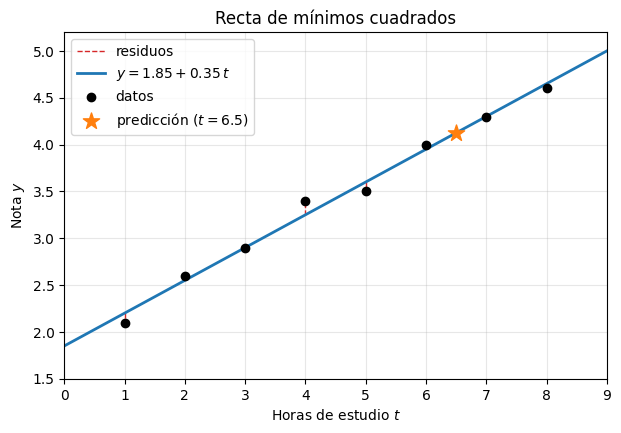

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Datos: horas de estudio (t) y nota del parcial (y)
t = np.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=float)
y = np.array([2.1, 2.6, 2.9, 3.4, 3.5, 4.0, 4.3, 4.6])

# a) Matriz de diseño: columna de unos y columna de t
A = np.column_stack([np.ones_like(t), t])
b = y

# b) Ecuaciones normales A^T A beta = A^T b
AtA = A.T @ A
Atb = A.T @ b
beta = np.linalg.solve(AtA, Atb)
b0, b1 = beta
print("A^T A =\n", AtA)
print("A^T b =", Atb)
print(f"Recta de mínimos cuadrados: y = {b0:.2f} + {b1:.2f} t")

# Comparación con la función de numpy
beta_lstsq = np.linalg.lstsq(A, b, rcond=None)[0]
print("np.linalg.lstsq:", beta_lstsq)

# c) Residuos y comprobación de ortogonalidad
y_hat = A @ beta
e = b - y_hat
print("Residuos e =", np.round(e, 4))
print("A^T e =", np.round(A.T @ e, 10))
print(f"Suma de cuadrados de los residuos = {e @ e:.4f}")

# d) Predicción
t_nuevo = 6.5
print(f"Nota predicha para {t_nuevo} horas: {b0 + b1 * t_nuevo:.3f}")

# e) Gráfica: datos, recta de regresión y residuos
tt = np.linspace(0, 9, 200)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.vlines(t, y_hat, y, colors="tab:red", linestyles="dashed", linewidth=1, label="residuos")
ax.plot(tt, b0 + b1 * tt, color="tab:blue", linewidth=2, label=f"$y = {b0:.2f} + {b1:.2f}\\,t$")
ax.scatter(t, y, color="black", zorder=3, label="datos")
ax.scatter([t_nuevo], [b0 + b1 * t_nuevo], marker="*", s=150, color="tab:orange", zorder=3,
           label=f"predicción ($t={t_nuevo}$)")
ax.set_xlabel("Horas de estudio $t$")
ax.set_ylabel("Nota $y$")
ax.set_title("Recta de mínimos cuadrados")
ax.set_xlim(0, 9)
ax.set_ylim(1.5, 5.2)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [5]:
import sympy as sp
sp.init_printing()